In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import matplotlib.patches as patches

import sys
sys.path.append('../src')

from lib_spike_control import *
from utils import * 

plt.style.use('tableau-colorblind10')

cmap = matplotlib.colormaps['viridis']
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

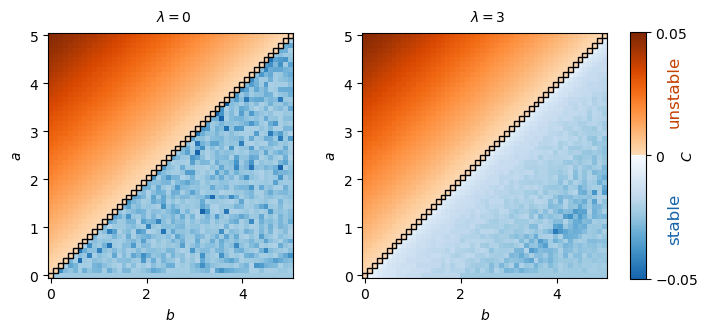

In [5]:
# Set subplots
fig = plt.figure(figsize=(8.5, 4))

outer_gs = gridspec.GridSpec(1, 3, width_ratios=[4, 4, 0.5], figure=fig, wspace=.4)

# Load precomputed growth matrix
cost_matrix_0 = np.load("../data/growth_matrix_na_50_nb_50_x0_50.5_leak_0.npy")
cost_matrix_1 = np.load("../data/growth_matrix_na_50_nb_50_x0_50.5_leak_3.npy")

a_values = np.linspace(0.0, 5, 50)
b_values = np.linspace(0.0, 5, 50)

X, Y = np.meshgrid(b_values, a_values)

vmin = np.nanmin(cost_matrix_0)
vmax = np.nanmax(cost_matrix_0)
vmin, vmax = -0.05, 5

neg_cmap = plt.cm.Blues_r   # darker blues for more negative
pos_cmap = plt.cm.Oranges      # darker reds for more positive

# Build a new colormap with a hard break at 0
# We combine half of each colormap, without blending in the middle
neg_colors = neg_cmap(np.linspace(0.2, 1.0, 128))  # skip very light tones
pos_colors = pos_cmap(np.linspace(0.2, 1.0, 128))

# Concatenate the two colormaps
stacked_colors = np.vstack((neg_colors, pos_colors))
discont_cmap = LinearSegmentedColormap.from_list("discont_bwr", stacked_colors)

norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

ax_left = fig.add_subplot(outer_gs[0])
ax_right = fig.add_subplot(outer_gs[1])

# Plot cost matrices
ax_left.pcolormesh(X, Y, cost_matrix_0, cmap=discont_cmap, shading='auto', norm=norm, rasterized=True)
c = ax_right.pcolormesh(X, Y, cost_matrix_1, cmap=discont_cmap, shading='auto', norm=norm, rasterized=True)

Z = cost_matrix_0
nx = Z.shape[1]
ny = Z.shape[0]

# Derive cell edge coordinates from centers (assuming uniform grid spacing)
x_centers = X[0, :]     # X-coordinates across one row
y_centers = Y[:, 0]     # Y-coordinates down one column

# Compute edges by midpoints between centers
x_edges = np.concatenate((
    [x_centers[0] - 0.5*(x_centers[1]-x_centers[0])],
    0.5*(x_centers[:-1] + x_centers[1:]),
    [x_centers[-1] + 0.5*(x_centers[-1]-x_centers[-2])]
))
y_edges = np.concatenate((
    [y_centers[0] - 0.5*(y_centers[1]-y_centers[0])],
    0.5*(y_centers[:-1] + y_centers[1:]),
    [y_centers[-1] + 0.5*(y_centers[-1]-y_centers[-2])]
))

# Draw borders around diagonal cells
for i in range(min(ny, nx)):
    x0, x1 = x_edges[i], x_edges[i+1]
    y0, y1 = y_edges[i], y_edges[i+1]
    rect_1 = patches.Rectangle(
        (x0, y0),
        x1 - x0,
        y1 - y0,
        linewidth=1,
        edgecolor='black',
        facecolor='none',
        zorder=10
    )
    rect_2 = patches.Rectangle(
        (x0, y0),
        x1 - x0,
        y1 - y0,
        linewidth=1,
        edgecolor='black',
        facecolor='none',
        zorder=10
    )
    ax_right.add_patch(rect_1)
    ax_left.add_patch(rect_2)


ax_right.set_xlabel('$b$', size=10)
ax_right.set_ylabel('$a$', size=10)

ax_left.set_xlabel('$b$', size=10)
ax_left.set_ylabel('$a$', size=10)

# Additional manipulation of colorbar position
ax_c  = fig.add_subplot(outer_gs[2])

cbar = plt.colorbar(c, cax=ax_c)

pos = ax_c.get_position()

height = 0.8
width = 0.5
new_pos = [pos.x0 - 1.5*pos.width, pos.y0 + (1-height)/2*pos.height, width*pos.width, height*pos.height]
ax_c.set_position(new_pos)

cbar.set_label(r'$C$', fontsize=10, labelpad=-13)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks((vmin,0,vmax))
cbar.set_ticklabels(('$-0.05$', '$0$', '$0.05$'))

ax_left.axis("scaled")
ax_right.axis("scaled")

ax_left.text(2.2,5.3, f'$\\lambda = 0$', fontsize=10)
ax_right.text(2.2,5.3, f'$\\lambda = 3$', fontsize=10)
ax_right.text(6.3,.72, 'stable', fontsize=12, color=neg_cmap(.2), rotation='vertical')
ax_right.text(6.3,3.15, 'unstable', fontsize=12, color=pos_cmap(.8), rotation='vertical')

plt.savefig('../plots/figure2b.png', dpi=400, bbox_inches='tight')